# For dataset exploration
1) Wiki multi-hop QA dataset
2) AmbigQA dataset

In [1]:
# Dataset exploration for Wiki multi-hop QA dataset
from code_base.wiki_loader_pyt import wiki_loader_pyt

# Constants
DATA_PATH = "/mnt/c/Users/prath/Documents/Uni(Tudelft)/MSc/MasterThesis/data/2wikimultihopQA"
SPLIT = "test"  # Change to "train" or "test" as needed

# Load dataframes
docs_df, topics_df, qrels_df = wiki_loader_pyt(DATA_PATH, SPLIT)

Processing corpus...


100%|██████████| 563424/563424 [00:00<00:00, 1466120.09it/s]


Building title to docno mapping...
Created docs_df with 560691 documents.

Processing test set for topics and qrels...


100%|██████████| 12576/12576 [00:00<00:00, 38255.11it/s]


Document DataFrame info after cleanup:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 560691 entries, 0 to 560690
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   docno   560691 non-null  object
 1   title   560691 non-null  object
 2   text    560691 non-null  object
dtypes: object(3)
memory usage: 12.8+ MB
None
/n/n
Created topics_df with 12576 queries.
Created qrels_df with 153435 relevance judgments.


Corpus (docs_df) Statistics:
Number of documents: 560691
Average document length: 412.75
Maximum document length: 19246
Minimum document length: 8


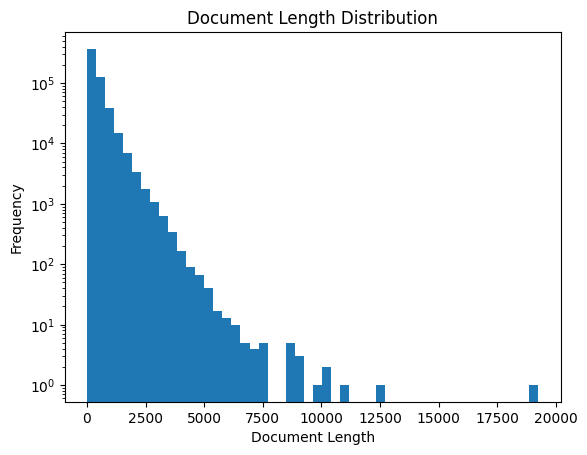


Queries (topics_df) Statistics:
Number of queries: 12576
Average query length: 68.36
Maximum query length: 171
Minimum query length: 22

Query Types Statistics:
type
compositional        5262
comparison           2986
bridge_comparison    2778
inference            1550
Name: count, dtype: int64


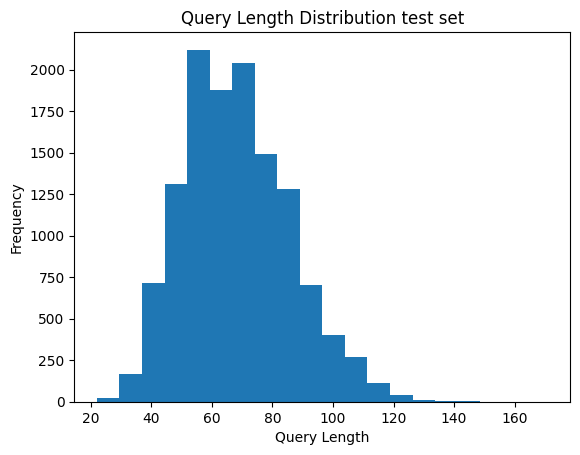


Query Relevance Judgments (qrels_df) Statistics:
Number of relevance judgments: 153435
Number of unique queries in qrels: 12576
Number of unique documents in qrels: 67842
Average number of relevant documents per query: 12.20


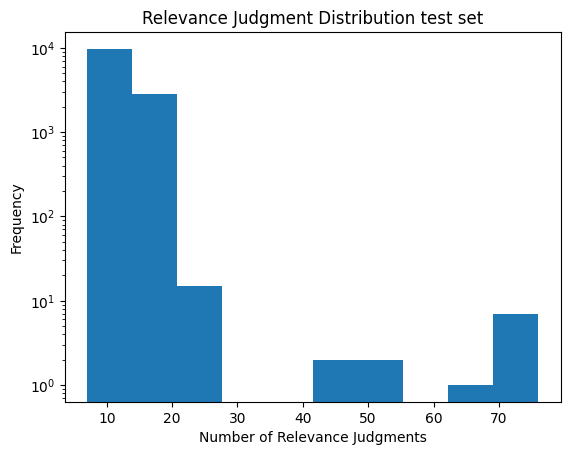

In [16]:
print("Corpus (docs_df) Statistics:")
docs_df['text_length'] = docs_df['text'].str.len()
print(f"Number of documents: {len(docs_df)}")
print(f"Average document length: {docs_df['text_length'].mean():.2f}")
print(f"Maximum document length: {docs_df['text_length'].max()}")
print(f"Minimum document length: {docs_df['text_length'].min()}")

#create a histogram of document lengths
import matplotlib.pyplot as plt

plt.hist(docs_df['text_length'], bins=50)
plt.title('Document Length Distribution')
plt.yscale('log')
plt.xlabel('Document Length')
plt.ylabel('Frequency')
plt.show()

# Queries (topics_df) statistics
print("\nQueries (topics_df) Statistics:")
topics_df['query_length'] = topics_df['query'].str.len()
print(f"Number of queries: {len(topics_df)}")
print(f"Average query length: {topics_df['query_length'].mean():.2f}")
print(f"Maximum query length: {topics_df['query_length'].max()}")
print(f"Minimum query length: {topics_df['query_length'].min()}")

print("\nQuery Types Statistics:")
print(topics_df['type'].value_counts())

plt.hist(topics_df['query_length'], bins=20)
plt.title(f'Query Length Distribution {SPLIT} set')
plt.xlabel('Query Length')
plt.ylabel('Frequency')
plt.show()

# Query relevance judgments (qrels_df) statistics
print("\nQuery Relevance Judgments (qrels_df) Statistics:")
print(f"Number of relevance judgments: {len(qrels_df)}")
print(f"Number of unique queries in qrels: {qrels_df['qid'].nunique()}")
print(f"Number of unique documents in qrels: {qrels_df['docno'].nunique()}")
avg_relevant_per_query = qrels_df.groupby('qid').size().mean()
print(f"Average number of relevant documents per query: {avg_relevant_per_query:.2f}")

#Create the distribution of relevance judgments per query
plt.hist(qrels_df['qid'].value_counts(), bins=10)
plt.title(f'Relevance Judgment Distribution {SPLIT} set')
plt.yscale('log')
plt.xlabel('Number of Relevance Judgments')
plt.ylabel('Frequency')
plt.show()

